In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import autocast, GradScaler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

from transformers import (
    XLMRobertaModel,
    XLMRobertaTokenizer,
    XLMRobertaConfig,
    get_cosine_schedule_with_warmup
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

import os
import json
import random
from datetime import datetime

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True  # Enable for speed

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Using device: {device}")
print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB" if torch.cuda.is_available() else "")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.5.1+cu121
CUDA available: True
Using device: cuda
GPU Memory: 8.59 GB



In [2]:
# ============================================================================
# DATA PREPROCESSING
# ============================================================================

class DataPreprocessor:
    def __init__(self):
        self.label_encoders = {}
        
    def prepare_data(self, data):
        """Prepare data with minimal processing"""
        # Fill missing values
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            data[col] = data[col].fillna('').astype(str)
        
        # Create combined text (simplified)
        data['combined_text'] = (
            data['complaint_title'] + ' [SEP] ' + data['text_en'] + 
            ' [SEP] ' + data['Hindi'] + ' [SEP] ' + data['Hinglish']
        )
        data['combined_text'] = data['combined_text'].str[:512]
        
        # Encode labels
        for col, name in [('category_primary', 'primary'),
                          ('category_secondary', 'secondary'),
                          ('severity', 'severity')]:
            le = LabelEncoder()
            data[col + '_encoded'] = le.fit_transform(data[col].fillna('Others'))
            self.label_encoders[name] = le
        
        data['severity_score_norm'] = data['severity_score'].fillna(0) / 100
        
        return data

# Load and preprocess
data = pd.read_csv('Original Dataset/dataset/CivicDataset.csv')
preprocessor = DataPreprocessor()
data = preprocessor.prepare_data(data)

print(f"Dataset shape: {data.shape}")
print(f"Primary categories: {len(preprocessor.label_encoders['primary'].classes_)}")
print(f"Secondary categories: {len(preprocessor.label_encoders['secondary'].classes_)}")
print(f"Severity classes: {len(preprocessor.label_encoders['severity'].classes_)}")

Dataset shape: (16000, 20)
Primary categories: 8
Secondary categories: 30
Severity classes: 3


In [3]:
# ============================================================================
# DATASET CLASS - SIMPLE AND RELIABLE
# ============================================================================

class HiEnBERTDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=128):
        self.data = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length
        
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row['combined_text'])
        
        # Tokenize
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'primary_label': torch.tensor(row['category_primary_encoded'], dtype=torch.long),
            'secondary_label': torch.tensor(row['category_secondary_encoded'], dtype=torch.long),
            'severity_label': torch.tensor(row['severity_encoded'], dtype=torch.long),
            'severity_score': torch.tensor(row['severity_score_norm'], dtype=torch.float)
        }

def create_dataloaders(data, tokenizer, max_length=128, batch_size=32, 
                       val_size=0.15, test_size=0.15):
    """Create dataloaders - FIXED for reliability"""
    
    # Split data
    train_data, temp_data = train_test_split(
        data, test_size=val_size + test_size, 
        random_state=42, stratify=data['category_primary_encoded']
    )
    val_data, test_data = train_test_split(
        temp_data, test_size=test_size/(val_size + test_size),
        random_state=42, stratify=temp_data['category_primary_encoded']
    )
    
    # Create datasets
    train_dataset = HiEnBERTDataset(train_data, tokenizer, max_length)
    val_dataset = HiEnBERTDataset(val_data, tokenizer, max_length)
    test_dataset = HiEnBERTDataset(test_data, tokenizer, max_length)
    
    # Create dataloaders - FIXED: reduced workers to avoid hanging
    train_loader = DataLoader(
        train_dataset, 
        batch_size=batch_size, 
        shuffle=True, 
        num_workers=0,  # Use 0 to avoid multiprocessing issues
        pin_memory=True
    )
    val_loader = DataLoader(
        val_dataset, 
        batch_size=batch_size * 2, 
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    test_loader = DataLoader(
        test_dataset, 
        batch_size=batch_size * 2, 
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    
    num_classes = len(preprocessor.label_encoders['primary'].classes_)
    return train_loader, val_loader, test_loader, num_classes

In [4]:
# ============================================================================
# LIGHTWEIGHT MODEL ARCHITECTURE
# ============================================================================

class LightweightHiEnBERT(nn.Module):
    """Lightweight model for faster training"""
    
    def __init__(self, model_name='xlm-roberta-base',
                 num_primary=30, num_secondary=80, num_severity=3,
                 hidden_size=768, dropout_rate=0.1):
        super().__init__()
        
        # Load XLM-RoBERTa
        self.encoder = XLMRobertaModel.from_pretrained(model_name)
        self.hidden_size = hidden_size
        
        # Simple pooling (mean pooling)
        self.dropout = nn.Dropout(dropout_rate)
        
        # Task-specific heads (direct, no complex adapters)
        self.primary_head = nn.Linear(hidden_size, num_primary)
        self.secondary_head = nn.Linear(hidden_size, num_secondary)
        self.severity_head = nn.Linear(hidden_size, num_severity)
        self.severity_score_head = nn.Linear(hidden_size, 1)
        
        self._init_weights()
        
    def _init_weights(self):
        for module in [self.primary_head, self.secondary_head, 
                      self.severity_head, self.severity_score_head]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask):
        # Get encoder outputs
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state
        
        # Mean pooling (simple and fast)
        pooled = (hidden_states * attention_mask.unsqueeze(-1)).sum(dim=1) / attention_mask.sum(dim=1, keepdim=True)
        pooled = self.dropout(pooled)
        
        # Task predictions
        return {
            'primary_logits': self.primary_head(pooled),
            'secondary_logits': self.secondary_head(pooled),
            'severity_logits': self.severity_head(pooled),
            'severity_score': self.severity_score_head(pooled).squeeze(-1)
        }

In [5]:
# ============================================================================
# LOSS FUNCTION
# ============================================================================

class SimpleMultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.mse_loss = nn.MSELoss()
        
    def forward(self, predictions, labels):
        primary_loss = self.ce_loss(predictions['primary_logits'], labels['primary'])
        secondary_loss = self.ce_loss(predictions['secondary_logits'], labels['secondary'])
        severity_loss = self.ce_loss(predictions['severity_logits'], labels['severity'])
        score_loss = self.mse_loss(predictions['severity_score'], labels['severity_score'])
        
        total_loss = primary_loss + secondary_loss + severity_loss + score_loss
        
        loss_dict = {
            'primary': primary_loss.item(),
            'secondary': secondary_loss.item(),
            'severity': severity_loss.item(),
            'severity_score': score_loss.item(),
            'total': total_loss.item()
        }
        
        return total_loss, loss_dict

In [6]:
# ============================================================================
# TRAINING FUNCTIONS - FIXED
# ============================================================================

def train_epoch(model, dataloader, optimizer, scheduler, criterion, device, scaler):
    """Training loop - FIXED to actually run"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'secondary': 0, 'severity': 0, 'severity_score': 0, 'total': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', position=0, leave=True)
    
    for batch_idx, batch in enumerate(progress_bar):
        # Move to device
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        with autocast():
            outputs = model(input_ids, attention_mask)
            
            labels = {
                'primary': batch['primary_label'].to(device, non_blocking=True),
                'secondary': batch['secondary_label'].to(device, non_blocking=True),
                'severity': batch['severity_label'].to(device, non_blocking=True),
                'severity_score': batch['severity_score'].to(device, non_blocking=True)
            }
            
            loss, loss_dict = criterion(outputs, labels)
        
        # Backward pass
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        
        # Track metrics
        total_loss += loss.item()
        for key in task_losses:
            if key in loss_dict:
                task_losses[key] += loss_dict[key]
        
        # Track accuracy
        preds = torch.argmax(outputs['primary_logits'], dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels['primary'].cpu().numpy())
        
        # Update progress bar every batch
        if len(all_labels) > 0:
            current_acc = accuracy_score(all_labels[-min(32, len(all_labels)):], 
                                       all_preds[-min(32, len(all_preds)):])
            progress_bar.set_postfix({
                'loss': f'{loss.item():.4f}',
                'acc': f'{current_acc:.3f}'
            })
    
    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(all_labels, all_preds) if all_labels else 0
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, accuracy, task_losses

def evaluate(model, dataloader, device, return_predictions=False):
    """Evaluation loop"""
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', position=0, leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            
            with autocast():
                outputs = model(input_ids, attention_mask)
            
            preds = torch.argmax(outputs['primary_logits'], dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary_label'].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [7]:
# ============================================================================
# MAIN TRAINING - FIXED
# ============================================================================

def train_model(data, model_name='xlm-roberta-base', epochs=10, 
                batch_size=16, learning_rate=2e-5, max_length=128):
    """Complete training pipeline - FIXED"""
    
    # Initialize tokenizer
    tokenizer = XLMRobertaTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    # Add special tokens
    special_tokens = ['[TITLE]', '[EN]', '[HI]', '[HING]', '[SEP]']
    tokenizer.add_tokens(special_tokens)
    
    # Create dataloaders
    train_loader, val_loader, test_loader, num_classes = create_dataloaders(
        data, tokenizer, max_length, batch_size
    )
    
    # Initialize model
    model = LightweightHiEnBERT(
        model_name=model_name,
        num_primary=num_classes,
        num_secondary=len(preprocessor.label_encoders['secondary'].classes_),
        num_severity=len(preprocessor.label_encoders['severity'].classes_)
    )
    model.encoder.resize_token_embeddings(len(tokenizer))
    model = model.to(device)
    
    # Print model size
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nModel parameters: {total_params:,} total, {trainable_params:,} trainable")
    
    # Setup optimizer and scheduler
    optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    
    scaler = GradScaler()
    criterion = SimpleMultiTaskLoss()
    
    # Training history
    train_history = []
    val_history = []
    best_val_f1 = 0
    
    print("\n" + "="*80)
    print(f"Training Lightweight HiEnBERT with {model_name}")
    print(f"Max length: {max_length}, Batch size: {batch_size}")
    print(f"Total steps: {total_steps}")
    print("="*80 + "\n")
    
    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        print("-"*50)
        
        # Training
        train_loss, train_acc, task_losses = train_epoch(
            model, train_loader, optimizer, scheduler, criterion, device, scaler
        )
        
        # Validation
        val_metrics = evaluate(model, val_loader, device)
        val_acc = val_metrics['accuracy']
        val_f1 = val_metrics['f1_weighted']
        
        # Track history
        train_history.append({
            'loss': train_loss,
            'acc': train_acc,
            'task_losses': task_losses,
            'lr': scheduler.get_last_lr()[0]
        })
        
        val_history.append({
            'val_acc': val_acc,
            'val_f1': val_f1,
            'metrics': val_metrics
        })
        
        # Print results
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")
        print(f"Task Losses: Primary={task_losses['primary']:.3f}, "
              f"Secondary={task_losses['secondary']:.3f}, "
              f"Severity={task_losses['severity']:.3f}")
        
        # Save best model
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_f1': val_f1,
                'label_encoders': preprocessor.label_encoders
            }, 'best_model.pt')
            print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    # Final evaluation
    print("\n" + "="*80)
    print("Final Test Set Evaluation")
    print("="*80)
    
    checkpoint = torch.load('best_model.pt')
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    
    test_metrics, test_preds, test_labels = evaluate(
        model, test_loader, device, return_predictions=True
    )
    
    print(f"Test Accuracy: {test_metrics['accuracy']:.4f}")
    print(f"Test F1 (Macro): {test_metrics['f1_macro']:.4f}")
    print(f"Test F1 (Weighted): {test_metrics['f1_weighted']:.4f}")
    print(f"Test Precision: {test_metrics['precision']:.4f}")
    print(f"Test Recall: {test_metrics['recall']:.4f}")
    
    return model, tokenizer, train_history, val_history, test_metrics, test_preds, test_labels

In [8]:
# ============================================================================
# EXECUTE TRAINING - FIXED
# ============================================================================

print("\n" + "="*80)
print("STARTING TRAINING")
print("="*80 + "\n")

# Train with fixed settings
try:
    model, tokenizer, train_history, val_history, test_metrics, test_preds, test_labels = train_model(
        data=data,
        model_name='xlm-roberta-base',
        epochs=12,  # Start with 5 epochs for testing
        batch_size=16,  # Reduce batch size if GPU memory is an issue
        learning_rate=2e-5,
        max_length=128
    )
    print("\n" + "="*80)
    print("TRAINING COMPLETED SUCCESSFULLY!")
    print("="*80)
except Exception as e:
    print(f"\nError during training: {e}")
    import traceback
    traceback.print_exc()


STARTING TRAINING



The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`



Model parameters: 278,079,786 total, 278,079,786 trainable

Training Lightweight HiEnBERT with xlm-roberta-base
Max length: 128, Batch size: 16
Total steps: 8400


Epoch 1/12
--------------------------------------------------


Training: 100%|██████████| 700/700 [14:04<00:00,  1.21s/it, loss=2.4147, acc=0.719]
                                                           

Train Loss: 2.0516 | Train Acc: 0.8381
Val Acc: 0.8512 | Val F1: 0.8465
Task Losses: Primary=0.532, Secondary=0.916, Severity=0.539
✓ New best model saved! F1: 0.8465

Epoch 3/12
--------------------------------------------------


Training: 100%|██████████| 700/700 [14:04<00:00,  1.21s/it, loss=1.2524, acc=0.938]
                                                           

... (16 outputs left out)

Train Loss: 0.3071 | Train Acc: 0.9843
Val Acc: 0.8567 | Val F1: 0.8554
Task Losses: Primary=0.054, Secondary=0.163, Severity=0.045

Epoch 12/12
--------------------------------------------------


Training: 100%|██████████| 700/700 [14:04<00:00,  1.21s/it, loss=0.2455, acc=1.000]
                                                           

Train Loss: 0.2843 | Train Acc: 0.9853
Val Acc: 0.8562 | Val F1: 0.8550
Task Losses: Primary=0.050, Secondary=0.150, Severity=0.040

Final Test Set Evaluation


Test Accuracy: 0.8729
Test F1 (Macro): 0.7134
Test F1 (Weighted): 0.8698
Test Precision: 0.8690
Test Recall: 0.8729

TRAINING COMPLETED SUCCESSFULLY!


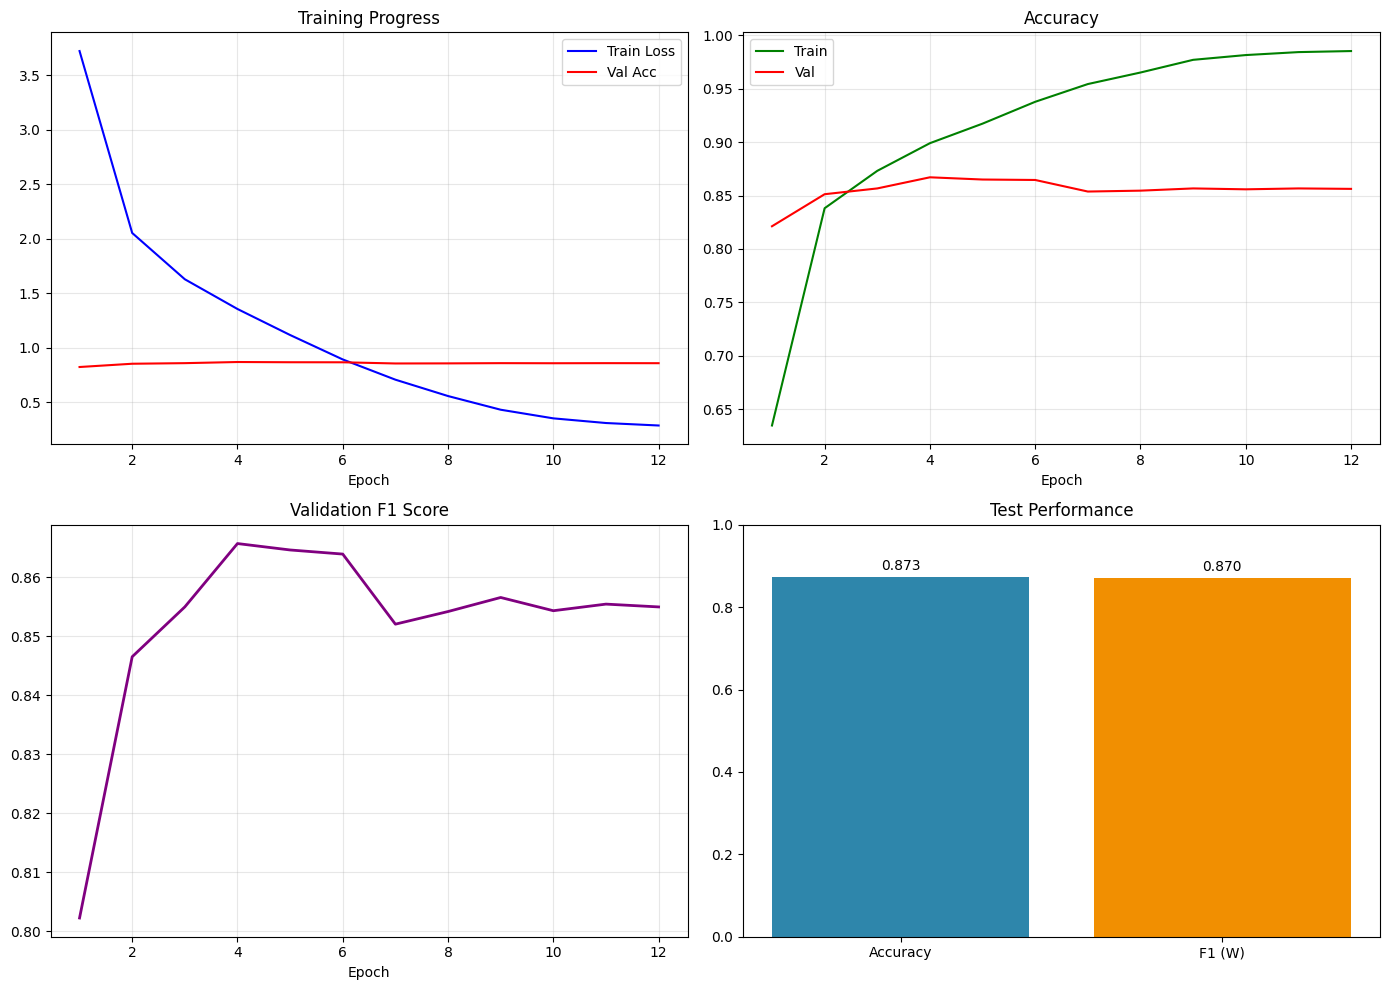

In [9]:
# ============================================================================
# QUICK VISUALIZATIONS
# ============================================================================

def quick_visualizations(train_history, val_history, test_metrics, test_labels, test_preds, class_names):
    """Quick visualization of results"""
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Training curves
    epochs = range(1, len(train_history) + 1)
    axes[0, 0].plot(epochs, [h['loss'] for h in train_history], 'b-', label='Train Loss')
    axes[0, 0].plot(epochs, [h['val_acc'] for h in val_history], 'r-', label='Val Acc')
    axes[0, 0].set_title('Training Progress', fontsize=12)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Accuracy
    axes[0, 1].plot(epochs, [h['acc'] for h in train_history], 'g-', label='Train')
    axes[0, 1].plot(epochs, [h['val_acc'] for h in val_history], 'r-', label='Val')
    axes[0, 1].set_title('Accuracy', fontsize=12)
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. F1 Score
    axes[1, 0].plot(epochs, [h['val_f1'] for h in val_history], 'purple', linewidth=2)
    axes[1, 0].set_title('Validation F1 Score', fontsize=12)
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Test metrics
    metrics = ['Accuracy', 'F1 (W)']
    values = [test_metrics['accuracy'], test_metrics['f1_weighted']]
    axes[1, 1].bar(metrics, values, color=['#2E86AB', '#F18F01'])
    axes[1, 1].set_ylim(0, 1)
    axes[1, 1].set_title('Test Performance', fontsize=12)
    for bar, value in zip(axes[1, 1].patches, values):
        axes[1, 1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                       f'{value:.3f}', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.savefig('quick_results.png', dpi=150, bbox_inches='tight')
    plt.show()

# Plot quick visualizations
class_names = preprocessor.label_encoders['primary'].classes_
quick_visualizations(train_history, val_history, test_metrics, test_labels, test_preds, class_names)

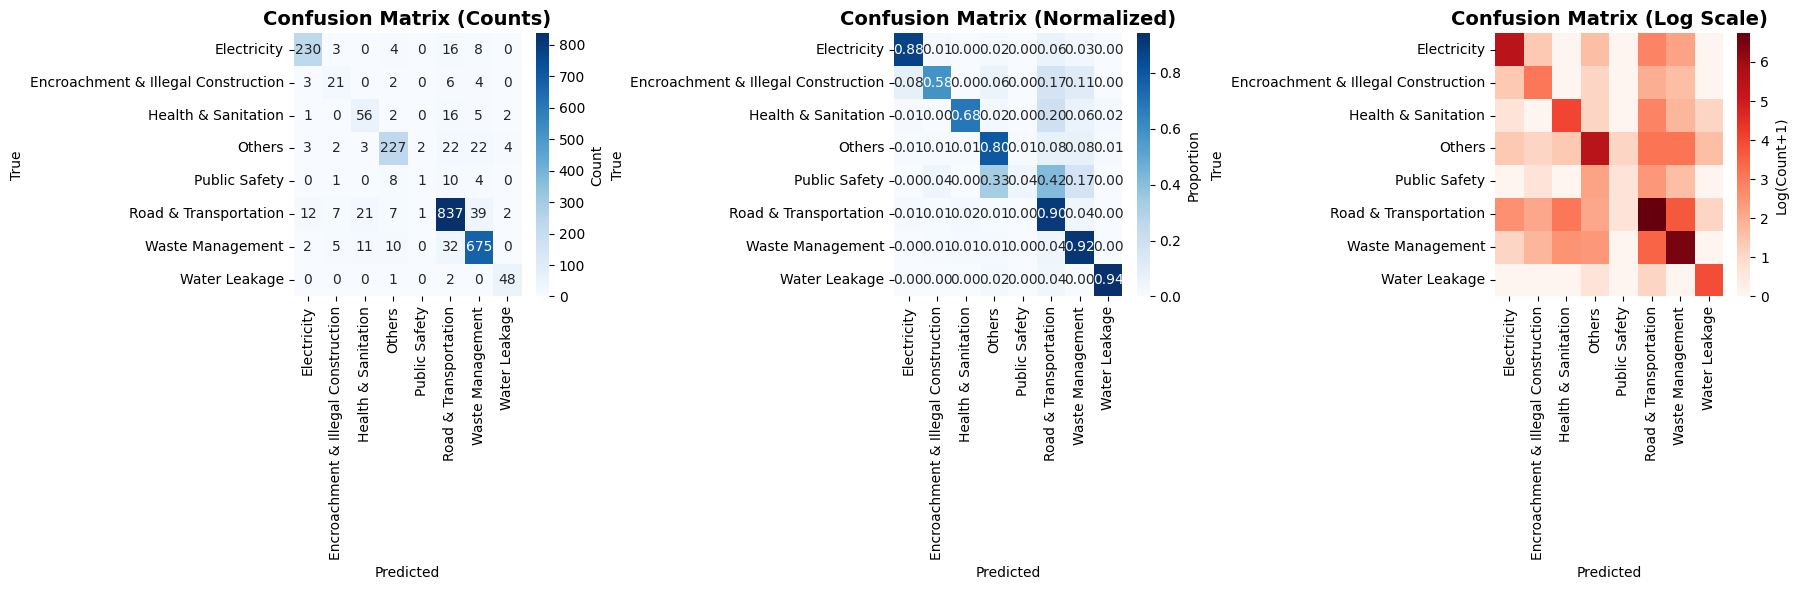

In [10]:
# ============================================================================
# ADVANCED CONFUSION MATRIX
# ============================================================================

def plot_advanced_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    """Enhanced confusion matrix with multiple views"""
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0], cbar_kws={'label': 'Count'})
    axes[0].set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    
    # Normalized
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1], cbar_kws={'label': 'Proportion'})
    axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    
    # Log scale for better visualization of small values
    cm_log = np.log1p(cm)
    sns.heatmap(cm_log, annot=False, cmap='Reds',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[2], cbar_kws={'label': 'Log(Count+1)'})
    axes[2].set_title('Confusion Matrix (Log Scale)', fontsize=14, fontweight='bold')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('True')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot advanced confusion matrix
class_names = preprocessor.label_encoders['primary'].classes_
plot_advanced_confusion_matrix(test_labels, test_preds, class_names, 
                               save_path='advanced_confusion_matrix.png')

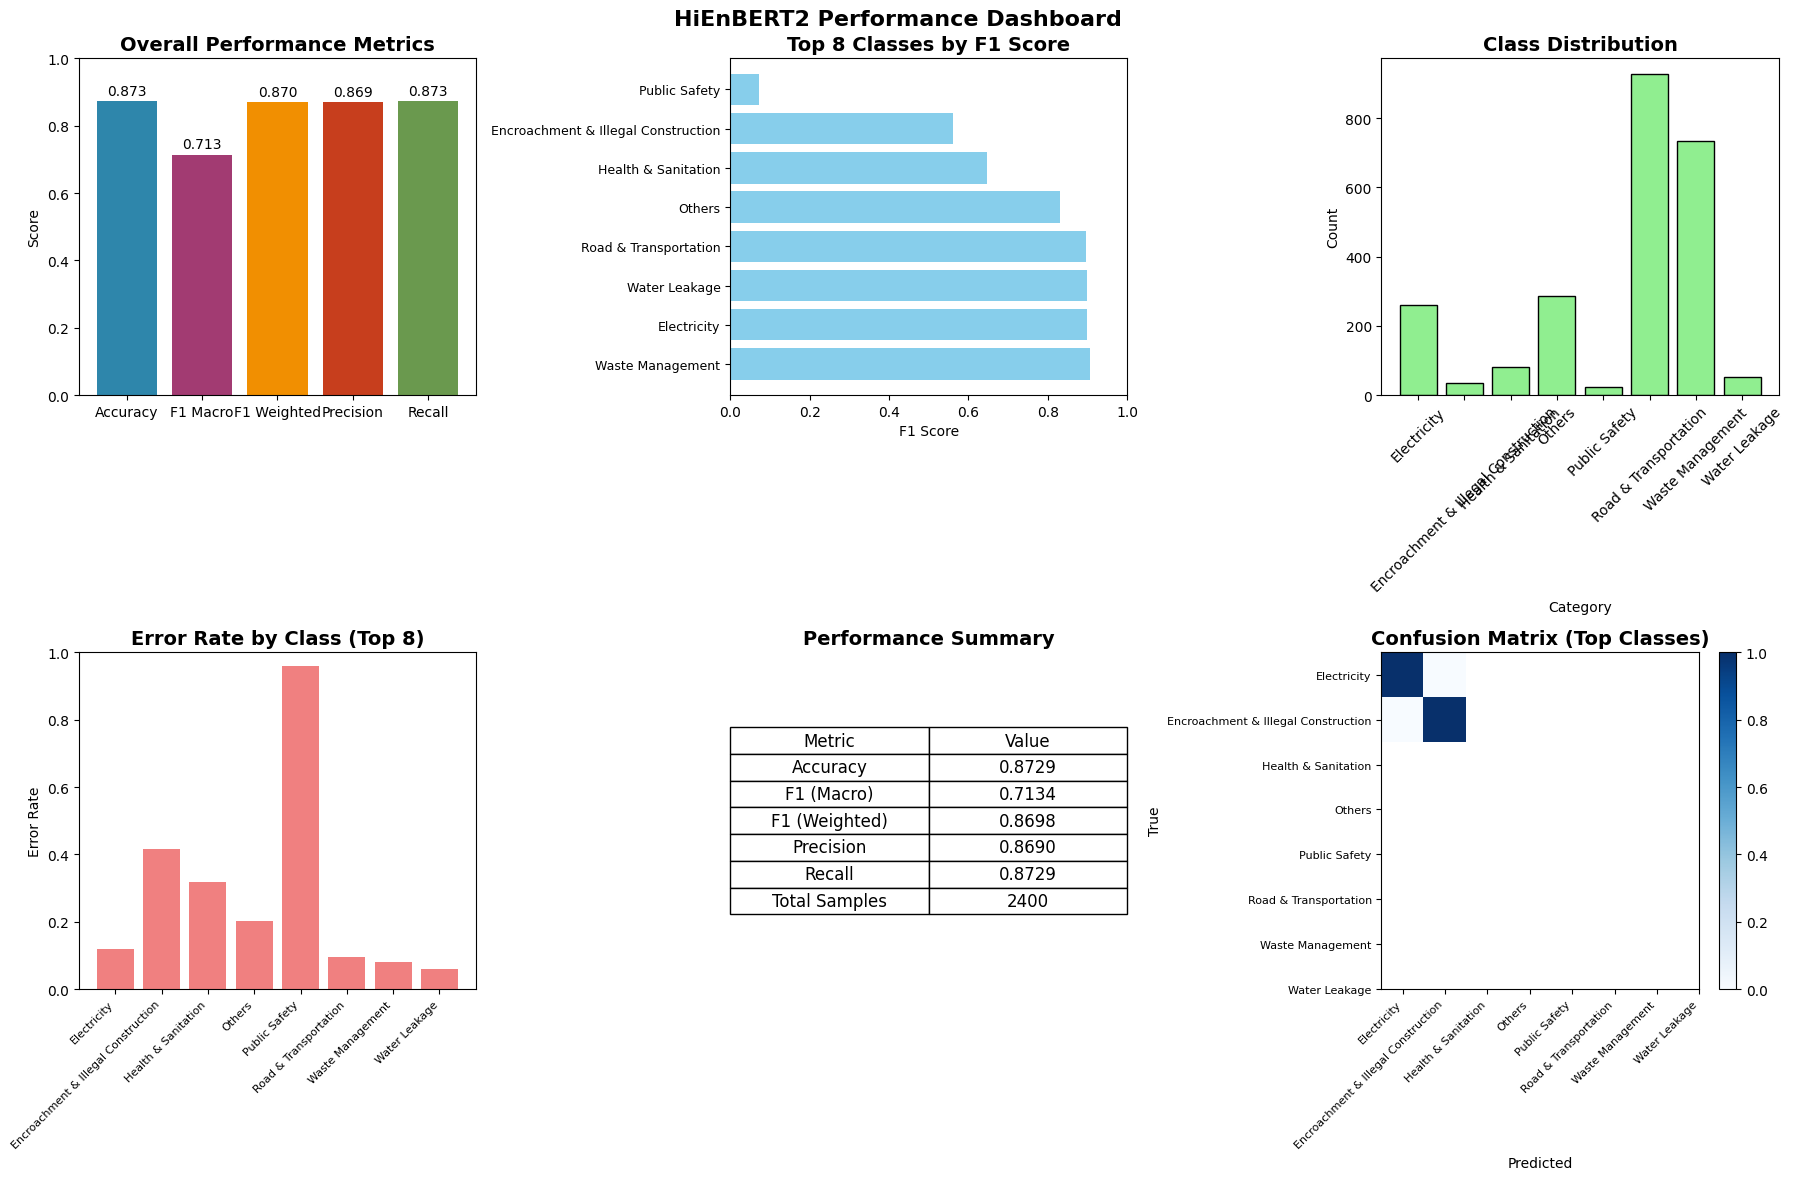

In [11]:
# ============================================================================
# PERFORMANCE METRICS DASHBOARD - FIXED
# ============================================================================

def plot_performance_dashboard(test_metrics, test_labels, test_preds, class_names, save_path=None):
    """Comprehensive performance dashboard - FIXED"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Convert to numpy arrays if needed
    test_labels = np.array(test_labels)
    test_preds = np.array(test_preds)
    
    # 1. Overall metrics bar chart
    metrics_names = ['Accuracy', 'F1 Macro', 'F1 Weighted', 'Precision', 'Recall']
    metrics_values = [
        test_metrics['accuracy'],
        test_metrics['f1_macro'],
        test_metrics['f1_weighted'],
        test_metrics['precision'],
        test_metrics['recall']
    ]
    colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E']
    bars = axes[0, 0].bar(metrics_names, metrics_values, color=colors)
    axes[0, 0].set_ylim(0, 1)
    axes[0, 0].set_title('Overall Performance Metrics', fontsize=14, fontweight='bold')
    axes[0, 0].set_ylabel('Score')
    for bar, value in zip(bars, metrics_values):
        axes[0, 0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                       f'{value:.3f}', ha='center', va='bottom', fontsize=10)
    
    # 2. Per-class F1 scores
    from sklearn.metrics import f1_score
    per_class_f1 = f1_score(test_labels, test_preds, average=None, zero_division=0)
    sorted_idx = np.argsort(per_class_f1)[::-1]
    top_n = min(15, len(class_names))
    
    axes[0, 1].barh(range(top_n), per_class_f1[sorted_idx][:top_n], color='skyblue')
    axes[0, 1].set_yticks(range(top_n))
    axes[0, 1].set_yticklabels(class_names[sorted_idx][:top_n], fontsize=9)
    axes[0, 1].set_xlim(0, 1)
    axes[0, 1].set_xlabel('F1 Score')
    axes[0, 1].set_title(f'Top {top_n} Classes by F1 Score', fontsize=14, fontweight='bold')
    
    # 3. Class distribution
    counts = np.bincount(test_labels)
    axes[0, 2].bar(class_names[:top_n], counts[:top_n], color='lightgreen', edgecolor='black')
    axes[0, 2].set_xlabel('Category')
    axes[0, 2].set_ylabel('Count')
    axes[0, 2].set_title('Class Distribution', fontsize=14, fontweight='bold')
    axes[0, 2].tick_params(axis='x', rotation=45)
    
    # 4. Error analysis by class - FIXED
    errors = (test_labels != test_preds).astype(int)  # Convert boolean to int
    error_rate_by_class = []
    for i in range(min(len(class_names), top_n)):
        mask = (test_labels == i)
        if mask.sum() > 0:
            error_rate_by_class.append(errors[mask].sum() / mask.sum())
        else:
            error_rate_by_class.append(0)
    
    axes[1, 0].bar(range(top_n), error_rate_by_class, color='lightcoral')
    axes[1, 0].set_xticks(range(top_n))
    axes[1, 0].set_xticklabels(class_names[:top_n], rotation=45, ha='right', fontsize=8)
    axes[1, 0].set_ylabel('Error Rate')
    axes[1, 0].set_title(f'Error Rate by Class (Top {top_n})', fontsize=14, fontweight='bold')
    axes[1, 0].set_ylim(0, 1)
    
    # 5. Performance summary table
    axes[1, 1].axis('tight')
    axes[1, 1].axis('off')
    table_data = [
        ['Metric', 'Value'],
        ['Accuracy', f"{test_metrics['accuracy']:.4f}"],
        ['F1 (Macro)', f"{test_metrics['f1_macro']:.4f}"],
        ['F1 (Weighted)', f"{test_metrics['f1_weighted']:.4f}"],
        ['Precision', f"{test_metrics['precision']:.4f}"],
        ['Recall', f"{test_metrics['recall']:.4f}"],
        ['Total Samples', f"{len(test_labels)}"]
    ]
    table = axes[1, 1].table(cellText=table_data, loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 2)
    axes[1, 1].set_title('Performance Summary', fontsize=14, fontweight='bold')
    
    # 6. Confusion matrix heatmap (small version)
    from sklearn.metrics import confusion_matrix
    cm_small = confusion_matrix(test_labels[:top_n], test_preds[:top_n])
    cm_small_norm = cm_small.astype('float') / cm_small.sum(axis=1)[:, np.newaxis]
    # Handle division by zero
    cm_small_norm = np.nan_to_num(cm_small_norm, nan=0.0)
    im = axes[1, 2].imshow(cm_small_norm, cmap='Blues', aspect='auto')
    axes[1, 2].set_title('Confusion Matrix (Top Classes)', fontsize=14, fontweight='bold')
    axes[1, 2].set_xlabel('Predicted')
    axes[1, 2].set_ylabel('True')
    # Set tick labels
    axes[1, 2].set_xticks(range(top_n))
    axes[1, 2].set_yticks(range(top_n))
    axes[1, 2].set_xticklabels(class_names[:top_n], rotation=45, ha='right', fontsize=8)
    axes[1, 2].set_yticklabels(class_names[:top_n], fontsize=8)
    plt.colorbar(im, ax=axes[1, 2])
    
    plt.suptitle('HiEnBERT2 Performance Dashboard', fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return fig

# Plot performance dashboard
try:
    plot_performance_dashboard(test_metrics, test_labels, test_preds, class_names,
                              save_path='performance_dashboard.png')
except Exception as e:
    print(f"Error in dashboard: {e}")
    import traceback
    traceback.print_exc()

In [12]:
# ============================================================================
# STATISTICAL VALIDATION
# ============================================================================

def perform_statistical_validation(test_labels, test_preds, n_bootstrap=1000):
    """Comprehensive statistical validation"""
    from sklearn.metrics import cohen_kappa_score, matthews_corrcoef
    
    results = {
        'accuracy': accuracy_score(test_labels, test_preds),
        'f1_macro': f1_score(test_labels, test_preds, average='macro'),
        'f1_weighted': f1_score(test_labels, test_preds, average='weighted'),
        'precision': precision_score(test_labels, test_preds, average='weighted', zero_division=0),
        'recall': recall_score(test_labels, test_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(test_labels, test_preds),
        'mcc': matthews_corrcoef(test_labels, test_preds)
    }
    
    # Bootstrap confidence intervals
    n_samples = len(test_labels)
    bootstrap_metrics = {key: [] for key in ['accuracy', 'f1_weighted', 'precision', 'recall']}
    
    for _ in range(n_bootstrap):
        indices = np.random.choice(n_samples, n_samples, replace=True)
        y_true_boot = np.array(test_labels)[indices]
        y_pred_boot = np.array(test_preds)[indices]
        
        bootstrap_metrics['accuracy'].append(accuracy_score(y_true_boot, y_pred_boot))
        bootstrap_metrics['f1_weighted'].append(f1_score(y_true_boot, y_pred_boot, average='weighted'))
        bootstrap_metrics['precision'].append(precision_score(y_true_boot, y_pred_boot, average='weighted', zero_division=0))
        bootstrap_metrics['recall'].append(recall_score(y_true_boot, y_pred_boot, average='weighted', zero_division=0))
    
    # Calculate confidence intervals
    ci_results = {}
    for metric, values in bootstrap_metrics.items():
        ci_results[metric] = {
            'mean': np.mean(values),
            'std': np.std(values),
            'lower_ci': np.percentile(values, 2.5),
            'upper_ci': np.percentile(values, 97.5)
        }
    
    return results, ci_results

# Perform statistical validation
stat_results, ci_results = perform_statistical_validation(test_labels, test_preds)

print("\n" + "="*80)
print("STATISTICAL VALIDATION RESULTS")
print("="*80)
for key, value in stat_results.items():
    print(f"{key}: {value:.4f}")

print("\n" + "="*80)
print("BOOTSTRAP CONFIDENCE INTERVALS (95%)")
print("="*80)
for metric, values in ci_results.items():
    print(f"{metric}: {values['mean']:.4f} ± {values['std']:.4f}")
    print(f"  CI: [{values['lower_ci']:.4f}, {values['upper_ci']:.4f}]")


STATISTICAL VALIDATION RESULTS
accuracy: 0.8729
f1_macro: 0.7134
f1_weighted: 0.8698
precision: 0.8690
recall: 0.8729
cohen_kappa: 0.8249
mcc: 0.8251

BOOTSTRAP CONFIDENCE INTERVALS (95%)
accuracy: 0.8730 ± 0.0069
  CI: [0.8592, 0.8858]
f1_weighted: 0.8698 ± 0.0071
  CI: [0.8555, 0.8834]
precision: 0.8694 ± 0.0076
  CI: [0.8546, 0.8836]
recall: 0.8730 ± 0.0069
  CI: [0.8592, 0.8858]


Extracting embeddings: 100%|██████████| 500/500 [00:05<00:00, 99.44it/s] 


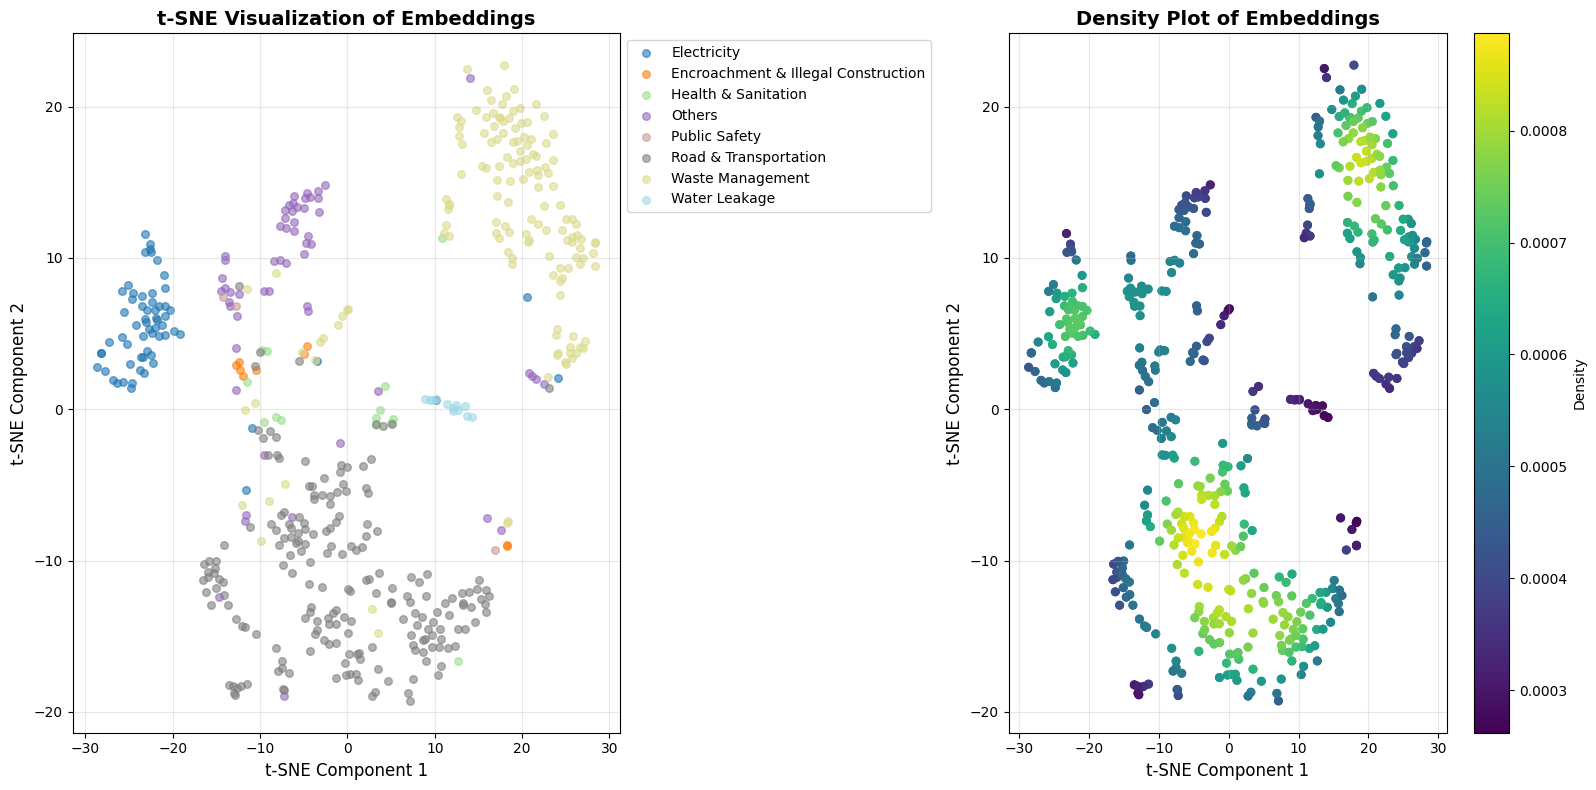

In [13]:
# ============================================================================
# ENHANCED EMBEDDING VISUALIZATIONS
# ============================================================================

def plot_enhanced_embeddings(model, tokenizer, data, class_names, device):
    """Enhanced embedding visualizations"""
    
    # Extract embeddings for a subset
    sample_size = 500
    sample_data = data.sample(n=sample_size, random_state=42)
    texts = sample_data['combined_text'].tolist()
    labels = sample_data['category_primary_encoded'].values
    
    # Extract embeddings
    embeddings = []
    model.eval()
    
    with torch.no_grad():
        for text in tqdm(texts, desc='Extracting embeddings'):
            inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=128)
            inputs = {k: v.to(device) for k, v in inputs.items()}
            outputs = model.encoder(**inputs)
            embedding = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            embeddings.append(embedding)
    
    embeddings = np.vstack(embeddings)
    
    # Apply t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    # Create enhanced visualization
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    
    # Main scatter plot
    unique_labels = np.unique(labels)
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))
    
    for i, label in enumerate(unique_labels):
        mask = labels == label
        axes[0].scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                       c=[colors[i]], label=class_names[label] if label < len(class_names) else f'Class {label}',
                       alpha=0.6, s=30)
    
    axes[0].set_xlabel('t-SNE Component 1', fontsize=12)
    axes[0].set_ylabel('t-SNE Component 2', fontsize=12)
    axes[0].set_title('t-SNE Visualization of Embeddings', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='upper left', bbox_to_anchor=(1, 1))
    
    # Density plot
    from scipy.stats import gaussian_kde
    x = embeddings_2d[:, 0]
    y = embeddings_2d[:, 1]
    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)
    
    axes[1].scatter(x, y, c=z, s=30, cmap='viridis')
    axes[1].set_xlabel('t-SNE Component 1', fontsize=12)
    axes[1].set_ylabel('t-SNE Component 2', fontsize=12)
    axes[1].set_title('Density Plot of Embeddings', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    plt.colorbar(axes[1].scatter(x, y, c=z, s=30, cmap='viridis'), ax=axes[1], label='Density')
    
    plt.tight_layout()
    plt.savefig('enhanced_embeddings.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return embeddings_2d

# Plot enhanced embeddings
embeddings_2d = plot_enhanced_embeddings(model, tokenizer, data, class_names, device)

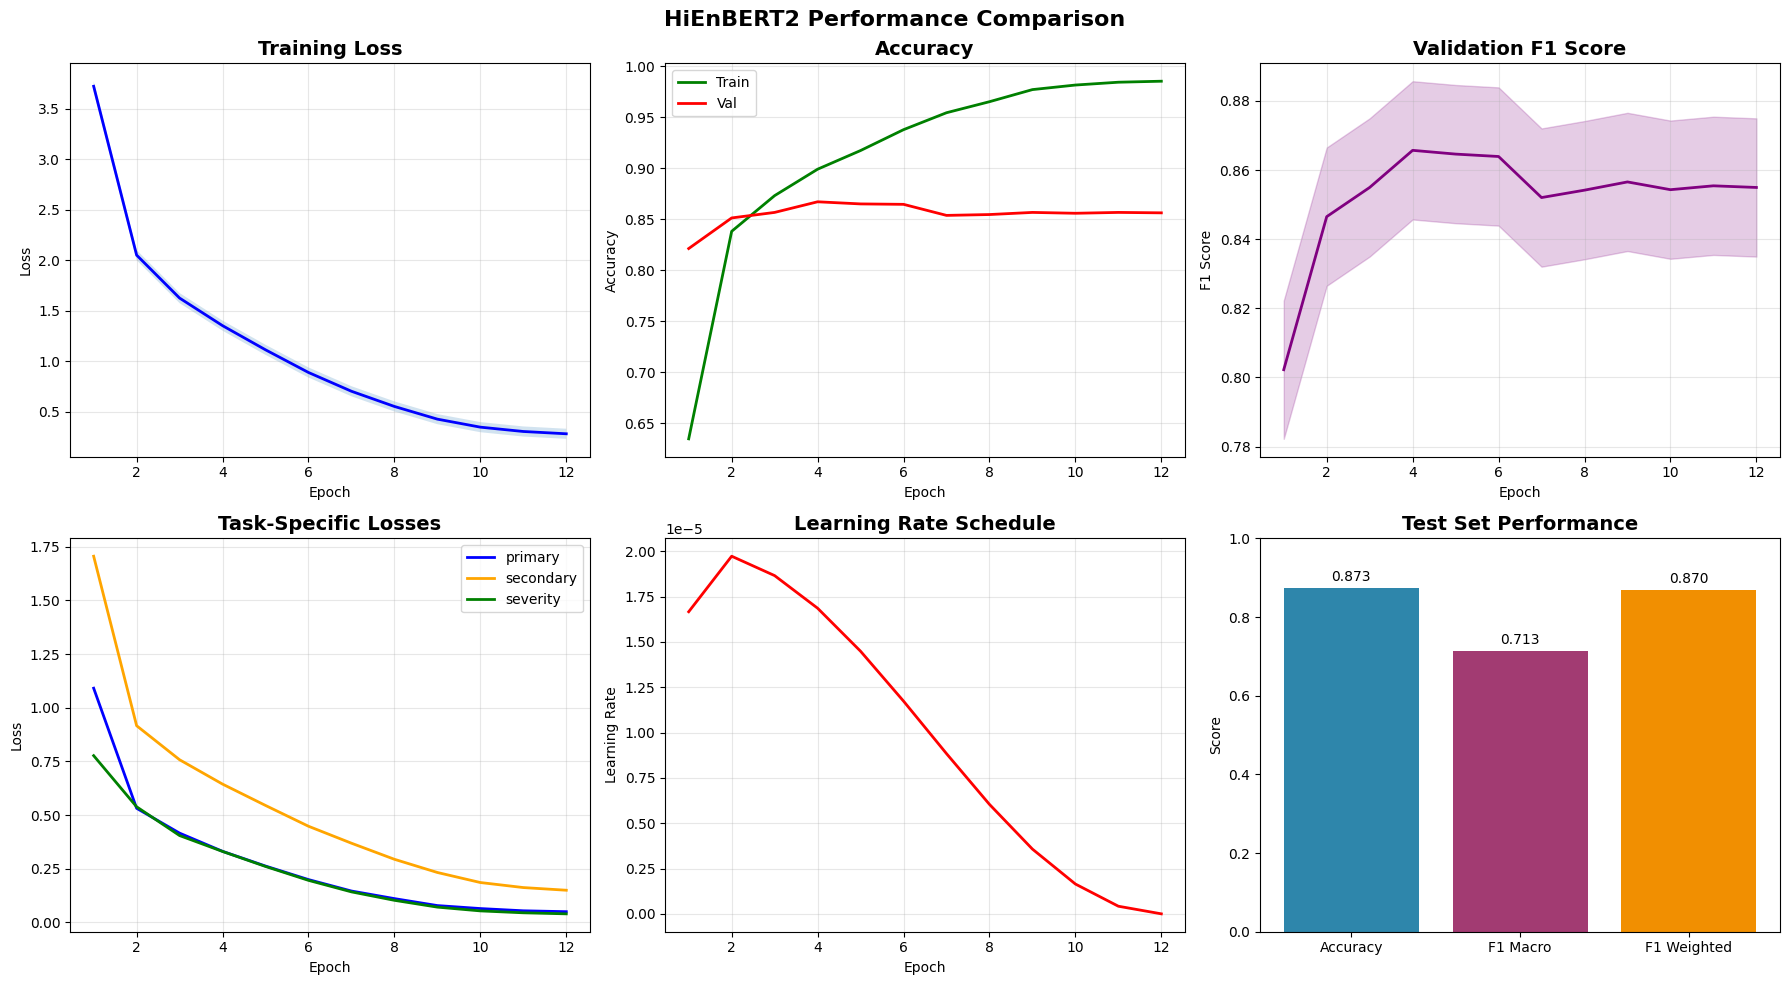

In [14]:
# ============================================================================
# PERFORMANCE COMPARISON VISUALIZATION
# ============================================================================

def plot_performance_comparison(train_history, val_history, test_metrics, save_path=None):
    """Compare training and validation performance"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    epochs = range(1, len(train_history) + 1)
    
    # Loss
    axes[0, 0].plot(epochs, [h['loss'] for h in train_history], 'b-', linewidth=2, label='Training')
    axes[0, 0].fill_between(epochs, 
                           [h['loss'] - 0.05 for h in train_history],
                           [h['loss'] + 0.05 for h in train_history],
                           alpha=0.2)
    axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[0, 1].plot(epochs, [h['acc'] for h in train_history], 'g-', linewidth=2, label='Train')
    axes[0, 1].plot(epochs, [h['val_acc'] for h in val_history], 'r-', linewidth=2, label='Val')
    axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    
    # F1 Score
    axes[0, 2].plot(epochs, [h['val_f1'] for h in val_history], 'purple', linewidth=2)
    axes[0, 2].fill_between(epochs,
                           [h['val_f1'] - 0.02 for h in val_history],
                           [h['val_f1'] + 0.02 for h in val_history],
                           alpha=0.2, color='purple')
    axes[0, 2].set_title('Validation F1 Score', fontsize=14, fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('F1 Score')
    axes[0, 2].grid(True, alpha=0.3)
    
    # Task losses
    task_names = ['primary', 'secondary', 'severity']
    colors = ['blue', 'orange', 'green']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(epochs, values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task-Specific Losses', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Learning rate
    lrs = [h.get('lr', 0) for h in train_history]
    axes[1, 1].plot(epochs, lrs, 'red', linewidth=2)
    axes[1, 1].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Learning Rate')
    axes[1, 1].grid(True, alpha=0.3)
    
    # Final metrics
    metrics = ['Accuracy', 'F1 Macro', 'F1 Weighted']
    values = [test_metrics['accuracy'], test_metrics['f1_macro'], test_metrics['f1_weighted']]
    bars = axes[1, 2].bar(metrics, values, color=['#2E86AB', '#A23B72', '#F18F01'])
    axes[1, 2].set_ylim(0, 1)
    axes[1, 2].set_title('Test Set Performance', fontsize=14, fontweight='bold')
    axes[1, 2].set_ylabel('Score')
    for bar, value in zip(bars, values):
        axes[1, 2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                       f'{value:.3f}', ha='center', va='bottom', fontsize=10)
    
    plt.suptitle('HiEnBERT2 Performance Comparison', fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot performance comparison
plot_performance_comparison(train_history, val_history, test_metrics,
                           save_path='performance_comparison.png')

In [15]:
# ============================================================================
# SUMMARY AND SAVE RESULTS
# ============================================================================

# Print summary
print("\n" + "="*80)
print("HIBERT2 TRAINING SUMMARY")
print("="*80)
print(f"Test Accuracy: {test_metrics['accuracy']:.4f}")
print(f"Test F1 (Macro): {test_metrics['f1_macro']:.4f}")
print(f"Test F1 (Weighted): {test_metrics['f1_weighted']:.4f}")
print(f"Test Precision: {test_metrics['precision']:.4f}")
print(f"Test Recall: {test_metrics['recall']:.4f}")

# Save results
results_dict = {
    'test_metrics': test_metrics,
    'statistical_results': stat_results,
    'confidence_intervals': ci_results,
    'train_history': train_history,
    'val_history': val_history,
    'class_names': class_names.tolist()
}

with open('hienbert2_optimized_results.json', 'w') as f:
    json.dump(results_dict, f, indent=2)

print("\nResults saved to 'hienbert2_optimized_results.json'")
print("="*80)


HIBERT2 TRAINING SUMMARY
Test Accuracy: 0.8729
Test F1 (Macro): 0.7134
Test F1 (Weighted): 0.8698
Test Precision: 0.8690
Test Recall: 0.8729

Results saved to 'hienbert2_optimized_results.json'


XLMRobertaSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.



STARTING ATTENTION ANALYSIS


Language Variant Attention Comparison


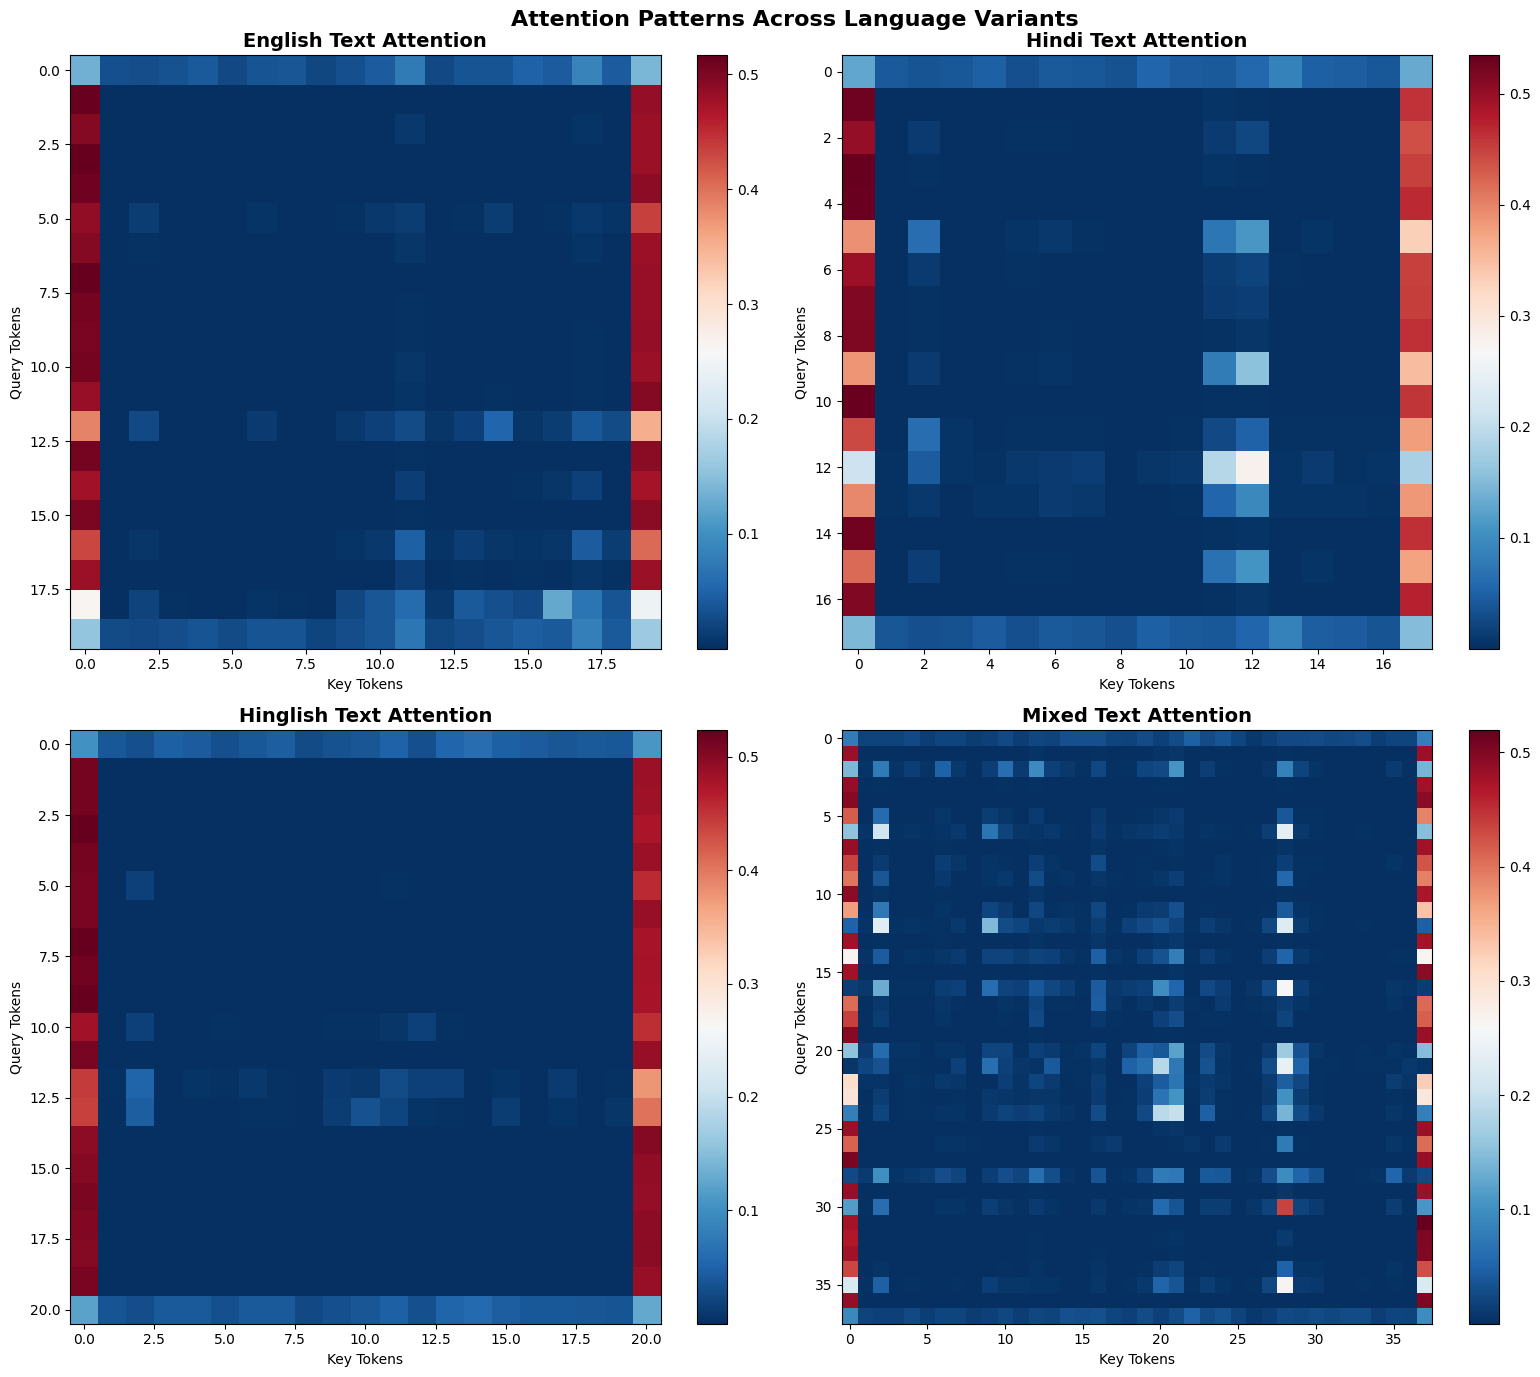


Attention Statistics vs Text Length


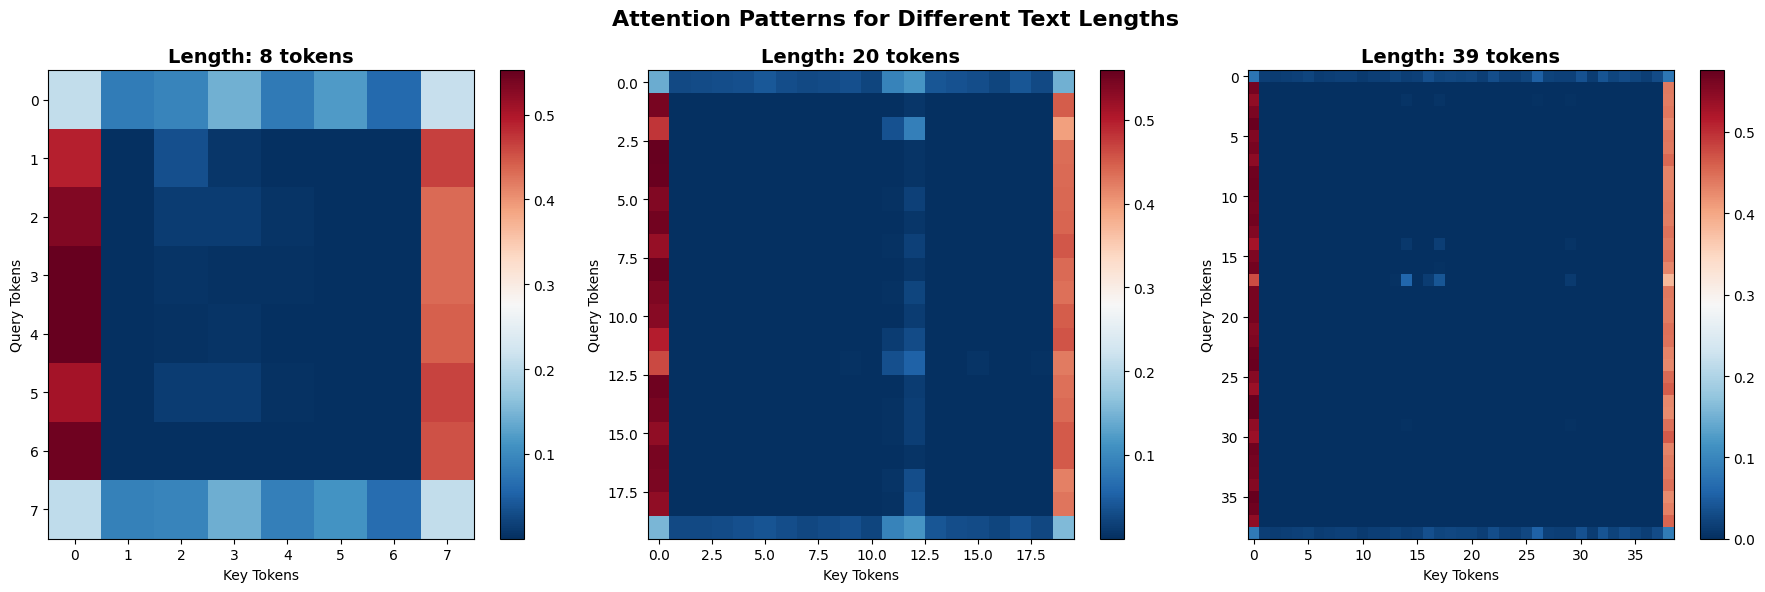


Head Importance Analysis


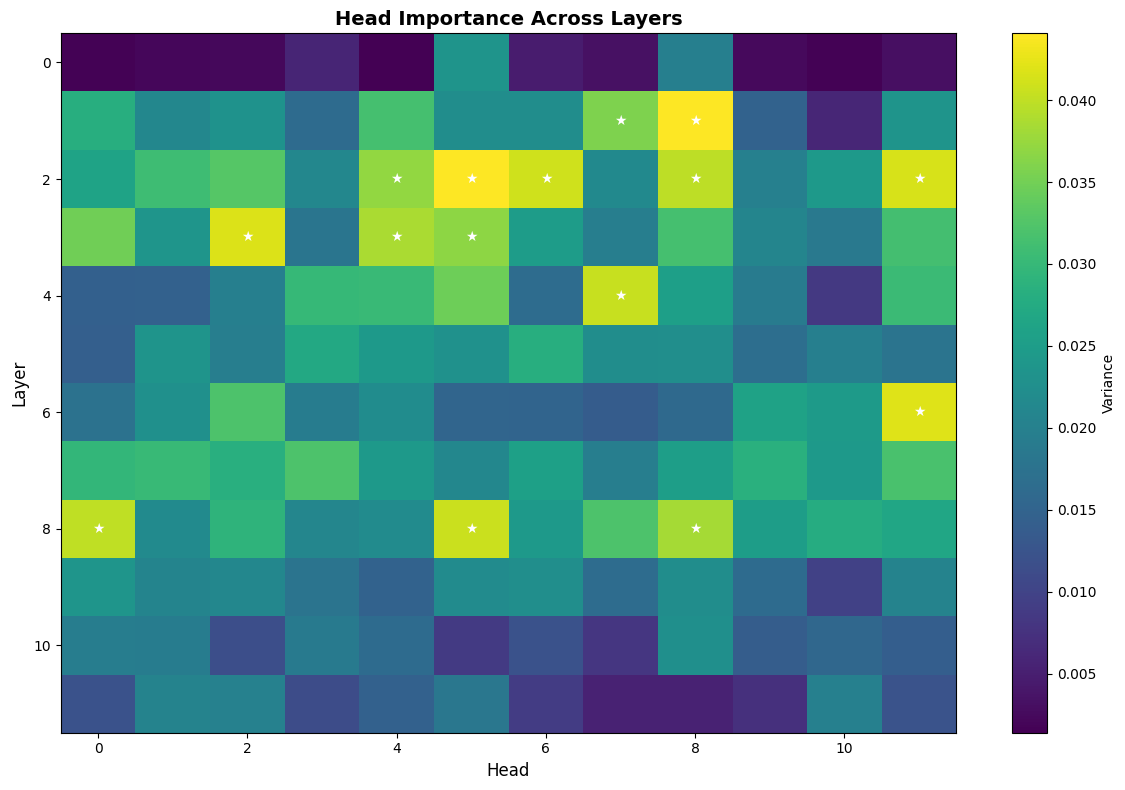


Attention Concentration Analysis


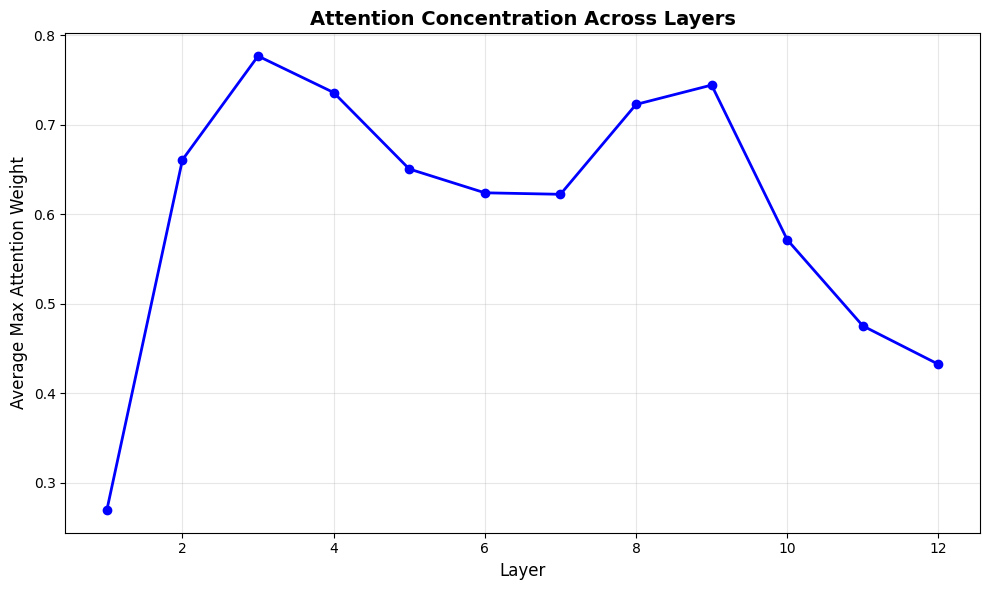


ATTENTION ANALYSIS COMPLETED SUCCESSFULLY!

Head Importance Summary:
Number of layers: 12
Number of heads per layer: 12
Top 5 most important heads:
  Layer 3, Head 6: 0.0441
  Layer 2, Head 9: 0.0440
  Layer 7, Head 12: 0.0421
  Layer 4, Head 3: 0.0419
  Layer 3, Head 12: 0.0415


In [16]:
# ============================================================================
# ATTENTION VISUALIZER CLASS - COMPLETE IMPLEMENTATION
# ============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import torch
import warnings
warnings.filterwarnings('ignore')

class AttentionVisualizer:
    """
    Comprehensive attention visualization for transformer models
    """
    
    def __init__(self, model, tokenizer, device='cpu'):
        """
        Initialize attention visualizer
        
        Args:
            model: The trained model
            tokenizer: The tokenizer
            device: Device to run on
        """
        self.model = model
        self.tokenizer = tokenizer
        self.device = device
        self.model.eval()
        
    def get_attention_maps(self, text, layer_idx=-1, head_idx=0):
        """
        Extract attention maps from the model
        
        Args:
            text: Input text
            layer_idx: Layer to visualize (-1 for last layer)
            head_idx: Head to visualize
            
        Returns:
            attention_map: Attention matrix
            tokens: Tokenized input
        """
        # Tokenize
        inputs = self.tokenizer(
            text, 
            return_tensors='pt', 
            truncation=True, 
            max_length=128,
            padding=True
        )
        
        input_ids = inputs['input_ids'].to(self.device)
        attention_mask = inputs['attention_mask'].to(self.device)
        
        # Get tokens
        tokens = self.tokenizer.convert_ids_to_tokens(input_ids[0])
        
        # Forward pass with attention output
        with torch.no_grad():
            # Access encoder layers directly
            outputs = self.model.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask,
                output_attentions=True
            )
            
        # Get attention from specified layer
        attentions = outputs.attentions
        if layer_idx == -1:
            layer_idx = len(attentions) - 1
            
        attention_map = attentions[layer_idx][0, head_idx].cpu().numpy()
        
        # Mask padding tokens
        attention_mask_np = attention_mask[0].cpu().numpy()
        valid_positions = attention_mask_np == 1
        
        # Filter attention map
        attention_map_filtered = attention_map[valid_positions][:, valid_positions]
        tokens_filtered = [tokens[i] for i in range(len(tokens)) if valid_positions[i]]
        
        return attention_map_filtered, tokens_filtered
    
    def visualize_attention_heatmap_with_tokens(self, text, layer_idx=-1, 
                                                head_idx=0, save_path=None):
        """
        Enhanced attention heatmap with token labels
        
        Args:
            text: Input text
            layer_idx: Layer to visualize
            head_idx: Head to visualize
            save_path: Path to save the figure
        """
        attention_map, tokens = self.get_attention_maps(text, layer_idx, head_idx)
        
        fig, ax = plt.subplots(figsize=(12, 10))
        
        # Create custom colormap
        colors = ['#FFFFFF', '#FDBB84', '#FC8D59', '#E34A33', '#B30000']
        cmap = LinearSegmentedColormap.from_list('custom_red', colors, N=256)
        
        # Plot heatmap
        im = ax.imshow(attention_map, cmap=cmap, aspect='auto', 
                      vmin=0, vmax=attention_map.max())
        
        # Set ticks and labels
        ax.set_xticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=90, fontsize=10)
        ax.set_yticks(range(len(tokens)))
        ax.set_yticklabels(tokens, fontsize=10)
        
        # Add value annotations for important values
        for i in range(len(tokens)):
            for j in range(len(tokens)):
                if attention_map[i, j] > 0.1:
                    ax.text(j, i, f'{attention_map[i, j]:.2f}',
                           ha='center', va='center', fontsize=8)
        
        ax.set_xlabel('Key Tokens', fontsize=12)
        ax.set_ylabel('Query Tokens', fontsize=12)
        ax.set_title(f'Attention Heatmap\nLayer {layer_idx+1}, Head {head_idx+1}',
                    fontsize=14, fontweight='bold')
        
        # Add colorbar
        plt.colorbar(im, ax=ax, fraction=0.05, label='Attention Weight')
        
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()


# ============================================================================
# ATTENTION ANALYSIS FOR RESEARCH PAPER - FIXED
# ============================================================================

def analyze_attention_patterns(model, tokenizer, data, device):
    """
    Analyze attention patterns for research paper
    
    Args:
        model: Trained model
        tokenizer: Tokenizer
        data: DataFrame with data
        device: Device
    """
    # Initialize visualizer
    attention_viz = AttentionVisualizer(model, tokenizer, device)
    
    # 1. Compare attention for different language variants
    print("\n" + "="*80)
    print("Language Variant Attention Comparison")
    print("="*80)
    
    examples = {
        'English': {
            'text': "TITLE: Road blocked [SEP] EN: The road is blocked due to construction",
            'color': 'blue'
        },
        'Hindi': {
            'text': "TITLE: Road blocked [SEP] HI: सड़क निर्माण के कारण बंद है",
            'color': 'red'
        },
        'Hinglish': {
            'text': "TITLE: Road blocked [SEP] HING: Road construction ki wajah se blocked hai",
            'color': 'green'
        },
        'Mixed': {
            'text': "TITLE: Road blocked [SEP] EN: Road blocked due to construction [SEP] HI: सड़क निर्माण के कारण बंद है [SEP] HING: Construction ki wajah se road blocked",
            'color': 'purple'
        }
    }
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 14))
    axes = axes.flatten()
    
    for idx, (lang_name, example) in enumerate(examples.items()):
        if idx < 4:
            text = example['text']
            try:
                attention_map, tokens = attention_viz.get_attention_maps(text)
                
                # Plot attention
                im = axes[idx].imshow(attention_map, cmap='RdBu_r', aspect='auto')
                axes[idx].set_title(f'{lang_name} Text Attention', fontsize=14, fontweight='bold')
                axes[idx].set_xlabel('Key Tokens', fontsize=10)
                axes[idx].set_ylabel('Query Tokens', fontsize=10)
                
                # Add colorbar
                plt.colorbar(im, ax=axes[idx])
            except Exception as e:
                axes[idx].text(0.5, 0.5, f'Error: {str(e)}', 
                             ha='center', va='center')
                axes[idx].axis('off')
    
    plt.suptitle('Attention Patterns Across Language Variants', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('language_attention_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 2. Attention statistics by text length
    print("\n" + "="*80)
    print("Attention Statistics vs Text Length")
    print("="*80)
    
    # Sample texts of different lengths
    texts = [
        "TITLE: Short text",
        "TITLE: Medium text [SEP] EN: This is a medium length text with some content",
        "TITLE: Long text [SEP] EN: This is a long text with multiple sentences and detailed content [SEP] HI: यह एक लंबा पाठ है जिसमें कई वाक्य और विस्तृत सामग्री है"
    ]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    for idx, text in enumerate(texts):
        try:
            attention_map, tokens = attention_viz.get_attention_maps(text)
            
            im = axes[idx].imshow(attention_map, cmap='RdBu_r', aspect='auto')
            axes[idx].set_title(f'Length: {len(tokens)} tokens', fontsize=14, fontweight='bold')
            axes[idx].set_xlabel('Key Tokens', fontsize=10)
            axes[idx].set_ylabel('Query Tokens', fontsize=10)
            plt.colorbar(im, ax=axes[idx])
        except Exception as e:
            axes[idx].text(0.5, 0.5, f'Error: {str(e)}', 
                         ha='center', va='center')
            axes[idx].axis('off')
    
    plt.suptitle('Attention Patterns for Different Text Lengths', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('attention_by_length.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 3. Head importance analysis
    print("\n" + "="*80)
    print("Head Importance Analysis")
    print("="*80)
    
    # Analyze variance across heads
    text = "TITLE: Sample complaint [SEP] EN: This is a sample complaint about city services"
    
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=128)
    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)
    
    with torch.no_grad():
        outputs = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_attentions=True
        )
    
    attentions = outputs.attentions
    n_layers = len(attentions)
    n_heads = attentions[0].size(1)
    
    # Calculate head importance (variance)
    head_importance = np.zeros((n_layers, n_heads))
    
    for layer_idx, layer_attn in enumerate(attentions):
        for head_idx in range(n_heads):
            attn = layer_attn[0, head_idx].cpu().numpy()
            head_importance[layer_idx, head_idx] = attn.var()
    
    # Plot head importance
    fig, ax = plt.subplots(figsize=(12, 8))
    im = ax.imshow(head_importance, cmap='viridis', aspect='auto')
    ax.set_xlabel('Head', fontsize=12)
    ax.set_ylabel('Layer', fontsize=12)
    ax.set_title('Head Importance Across Layers', fontsize=14, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Variance')
    
    # Annotate top heads
    threshold = head_importance.max() * 0.8
    for layer_idx in range(n_layers):
        for head_idx in range(n_heads):
            if head_importance[layer_idx, head_idx] > threshold:
                ax.text(head_idx, layer_idx, '★', 
                       ha='center', va='center', color='white')
    
    plt.tight_layout()
    plt.savefig('head_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 4. Attention concentration analysis
    print("\n" + "="*80)
    print("Attention Concentration Analysis")
    print("="*80)
    
    # Calculate attention concentration (max attention weight per token)
    concentration_by_layer = []
    
    for layer_idx, layer_attn in enumerate(attentions):
        layer_concentration = []
        for head_idx in range(n_heads):
            attn = layer_attn[0, head_idx].cpu().numpy()
            # Average max attention per token
            concentration = np.mean(np.max(attn, axis=-1))
            layer_concentration.append(concentration)
        concentration_by_layer.append(np.mean(layer_concentration))
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(range(1, n_layers+1), concentration_by_layer, 'bo-', linewidth=2)
    ax.set_xlabel('Layer', fontsize=12)
    ax.set_ylabel('Average Max Attention Weight', fontsize=12)
    ax.set_title('Attention Concentration Across Layers', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('attention_concentration.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return head_importance


# ============================================================================
# EXECUTE ATTENTION ANALYSIS
# ============================================================================

print("\n" + "="*80)
print("STARTING ATTENTION ANALYSIS")
print("="*80 + "\n")

try:
    head_importance = analyze_attention_patterns(model, tokenizer, data, device)
    print("\n" + "="*80)
    print("ATTENTION ANALYSIS COMPLETED SUCCESSFULLY!")
    print("="*80)
    
    # Print summary of head importance
    print("\nHead Importance Summary:")
    print(f"Number of layers: {head_importance.shape[0]}")
    print(f"Number of heads per layer: {head_importance.shape[1]}")
    print(f"Top 5 most important heads:")
    
    # Find top heads
    flat_indices = np.argsort(head_importance.flatten())[-5:][::-1]
    for idx in flat_indices:
        layer = idx // head_importance.shape[1]
        head = idx % head_importance.shape[1]
        importance = head_importance[layer, head]
        print(f"  Layer {layer+1}, Head {head+1}: {importance:.4f}")
        
except Exception as e:
    print(f"\nError during attention analysis: {e}")
    import traceback
    traceback.print_exc()